# Exploració de dades
Exploració de dades inicials. Inclou plots individuals (P0002) i grand average sobre tots els subjectes. Es repliquen plots similars que a l'article de Binocular Rivarly: Evaluating the Role of Theta Power as 
a Neural Index of Conflict (A. Drew, J. San-Segundo, S. Soto-Faraco, M. Torralba Cuello), entre altres.

In [1]:
import sys
from pathlib import Path
from google.colab import drive

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    drive.mount("/content/drive")
    possible_paths = [
        Path("/content/drive/Shareddrives/TFG_Nils_2026"),
        Path("/content/drive/MyDrive/TFG_Nils_2026"),
    ]
    BASE_DIR = next((p for p in possible_paths if p.exists()), possible_paths[0])
    DATA_DIR = BASE_DIR / "02_Data" / "01_Preprocessed_epochs"
    META_DIR = BASE_DIR / "02_Data" / "02_meta"
else:
    BASE_DIR = Path(".").resolve()
    DATA_DIR = BASE_DIR / "data"
    META_DIR = BASE_DIR / "docs"

print(f"Entorn : {'Colab' if IN_COLAB else 'Local'}")
print(f"Dades  : {DATA_DIR} → {'✅' if DATA_DIR.exists() else '❌'}")
if DATA_DIR.exists():
    fitxers = sorted(DATA_DIR.glob("*.fif"))
    print(f"Subjectes disponibles ({len(fitxers)}): {[f.name for f in fitxers]}")

Mounted at /content/drive
Entorn : Colab
Dades  : /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs → ✅
Subjectes disponibles (47): ['P0002.fif', 'P0003.fif', 'P0004.fif', 'P0005.fif', 'P0009.fif', 'P008.fif', 'P010.fif', 'P011.fif', 'P013.fif', 'P014.fif', 'P015.fif', 'P016.fif', 'P017.fif', 'P020.fif', 'P021.fif', 'P022.fif', 'P023.fif', 'P024.fif', 'P025.fif', 'P027.fif', 'P028.fif', 'P029.fif', 'P030.fif', 'P031.fif', 'P033.fif', 'P035.fif', 'P039.fif', 'P040.fif', 'P041.fif', 'P044.fif', 'P045.fif', 'P046.fif', 'P048.fif', 'P051.fif', 'P053.fif', 'P056.fif', 'P057.fif', 'P058.fif', 'P060.fif', 'P061.fif', 'P062.fif', 'P063.fif', 'P065.fif', 'P066.fif', 'P067.fif', 'P068.fif', 'P069.fif']


In [2]:
%pip install -q mne

import gc
import mne
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
from matplotlib.patches import Rectangle
import warnings

# Filtrem només l'avís que conté el text sobre les convencions de noms de fitxers
warnings.filterwarnings(
    'ignore', 
    category=RuntimeWarning, 
    module='mne', 
    message=".*does not conform to MNE naming conventions.*"
)

mne.set_log_level('WARNING')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 68.4 MB/s eta 0:00:00:00:010:01


In [3]:
# Paràmetres globals

# Agrupació d'events: els noms al fitxer són 'event_1', 'event_2', ...
# Left eye | Right eye | Response | Codi
#   Red    |   Red     |  Red     |  1  → Congruent
#   Green  |   Green   |  Green   |  2  → Congruent
#   Red    |   Green   |  Red     |  3  → Incongruent Pur
#   Green  |   Red     |  Red     |  4  → Incongruent Pur
#   Red    |   Green   |  Green   |  5  → Incongruent Pur
#   Green  |   Red     |  Green   |  6  → Incongruent Pur
#   Red    |   Green   |  Both    |  7  → Incongruent Mixt
#   Green  |   Red     |  Both    |  8  → Incongruent Mixt
#   9–12                               → Errors (ignorats)

COND_EVENTS = {
    "Congruent": ["event_1", "event_2"],
    "Incongruent_Pur": ["event_3", "event_4", "event_5", "event_6"],
    "Incongruent_Mixt": ["event_7", "event_8"],
}

ROI_FRONTAL = ["Fz", "FCz", "Cz"]
ROI_PO = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2"]

# Finestres de temps
TRIAL_START = -0.74
TRIAL_END = 1.5
FULL_TRIAL = (TRIAL_START, TRIAL_END)
BASELINE = (-0.74, -0.24)
RAMP_UP = (-0.24, 0.0)
STIM_ONSET = (0.0, 1.5)
STIM_OFFSET = (1.5, 2.0)

FINESTRA_1 = (0.0, 0.5)
FINESTRA_2 = (0.5, 1.0)
FINESTRA_3 = (1.0, 1.5)

COLORS = {"Congruent": "steelblue", "Incongruent_Pur": "darkorange", "Incongruent_Mixt": "forestgreen"}
LABELS = {
    "Congruent": "Congruent (C)",
    "Incongruent_Pur": "Incongruent Pur (IP)",
    "Incongruent_Mixt": "Incongruent Mixt (IM)",
}

FREQS_THETA = np.arange(5, 8)
FREQS_ALPHA = np.arange(8, 13)
FREQS_WIDE = np.arange(2, 21)

# STFT parameters
WIN_SEC = 0.5  # 500 ms de finestra
HOP_SEC = 0.02  # 20 ms de salt

In [4]:
# ── Funcions reutilitzables ─────────────────────────────────────────────────────
def load_subject(fif_path):
    """Carrega un .fif, corregeix els tipus de canal i retorna epochs_all + epochs_cond."""
    ep = mne.read_epochs(fif_path, preload=True, verbose=False)
    # Corregir unitats i tipus (surten com a 'misc' del preprocessat)
    for ch in ep.info["chs"]:
        ch["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
    ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")

    cond = {}
    for cond_name, event_names in COND_EVENTS.items():
        existing = [n for n in event_names if n in ep.event_id]
        if existing:
            cond[cond_name] = ep[existing]
    return ep, cond


def count_trials_by_condition(fif_path, cond_events=COND_EVENTS):
    """Compta trials per condició sense carregar el senyal EEG en memòria."""
    ep = mne.read_epochs(fif_path, preload=False, verbose=False)
    try:
        event_codes = ep.events[:, 2]
        event_id = ep.event_id
        counts = {}
        for cond_name, event_names in cond_events.items():
            codes = [event_id[n] for n in event_names if n in event_id]
            counts[cond_name] = int(np.isin(event_codes, codes).sum()) if codes else 0
        return counts
    finally:
        del ep


def stft_power_db(ep, picks, freqs=FREQS_WIDE, baseline=BASELINE):
    """STFT per epoch/canal amb finestra Hann, retornant potència baseline-corregida en dB."""
    x = ep.copy().pick(picks).get_data().astype(np.float32, copy=False)  # (n_epochs, n_ch, n_times)
    sfreq = ep.info["sfreq"]

    nperseg = int(round(WIN_SEC * sfreq))
    hop = int(round(HOP_SEC * sfreq))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, int(round(sfreq)))  # resolució ~1 Hz mantenint finestra de 500 ms

    f, t, Z = stft(
        x,
        fs=sfreq,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        boundary="zeros",
        padded=True,
        axis=-1,
    )
    power = np.abs(Z) ** 2  # (n_epochs, n_ch, n_freq, n_t)

    # Selecció de freqüències enteres 2..20 Hz
    freq_targets = np.asarray(freqs)
    freq_idx = np.array([np.argmin(np.abs(f - fr)) for fr in freq_targets])
    f_sel = f[freq_idx]
    power = power[:, :, freq_idx, :]

    times = ep.tmin + t
    bmask = (times >= baseline[0]) & (times <= baseline[1])
    b = power[..., bmask].mean(axis=-1, keepdims=True)
    power_db = 10 * np.log10((power + 1e-20) / (b + 1e-20))

    return f_sel, times, power_db


def stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4):
    """Mitjana TFR (dB) sobre epochs i canals processant canals en blocs per reduir RAM."""
    ch_names = ep.ch_names
    n_ch = len(ch_names)
    acc = None
    f_ref, t_ref = None, None

    for start in range(0, n_ch, ch_block):
        picks = ch_names[start : start + ch_block]
        f, t, p_db = stft_power_db(ep, picks=picks, freqs=freqs, baseline=baseline)
        block_mean = p_db.mean(axis=(0, 1))  # (n_freq, n_t), promig epochs+canals del bloc

        if acc is None:
            acc = np.zeros_like(block_mean)
            f_ref, t_ref = f, t

        acc += block_mean * len(picks)  # ponderem per nombre de canals del bloc
        del p_db, block_mean
        gc.collect()

    return f_ref, t_ref, acc / n_ch


def stft_band_timecourse(ep, picks, band, baseline=BASELINE):
    """Time-course de banda (dB) promig sobre epochs/canals/freqs dins la banda."""
    f, times, power_db = stft_power_db(ep, picks=picks, freqs=FREQS_WIDE, baseline=baseline)
    fmask = (f >= band[0]) & (f <= band[1])
    band_db = power_db[:, :, fmask, :]
    mean_ts = band_db.mean(axis=(0, 1, 2))
    sem_ts = band_db.std(axis=(0, 1, 2)) / np.sqrt(band_db.shape[0])
    return times, mean_ts, sem_ts

## Càrrega de dades
Aquesta cel·la carrega només el subjecte de treball per a l'exploració individual. Les anàlisis de grand average recorren la resta de subjectes un a un per evitar problemes de memòria.

In [5]:
SUBJ = "P0002"
epochs_all, epochs_cond = load_subject(DATA_DIR / f"{SUBJ}.fif")

print(f"Subjecte carregat en memòria: {SUBJ}")
print(f"Temps   : {epochs_all.tmin:.3f} → {epochs_all.tmax:.3f} s")
print(f'Mostreig: {epochs_all.info["sfreq"]} Hz  |  Canals: {len(epochs_all.ch_names)}')
for cond, ep in epochs_cond.items():
    print(f"  {cond:20s}: {len(ep):3d} trials")

Subjecte carregat en memòria: P0002
Temps   : -1.240 → 2.000 s
Mostreig: 500.0 Hz  |  Canals: 60
  Congruent           : 144 trials
  Incongruent_Pur     : 133 trials
  Incongruent_Mixt    : 107 trials


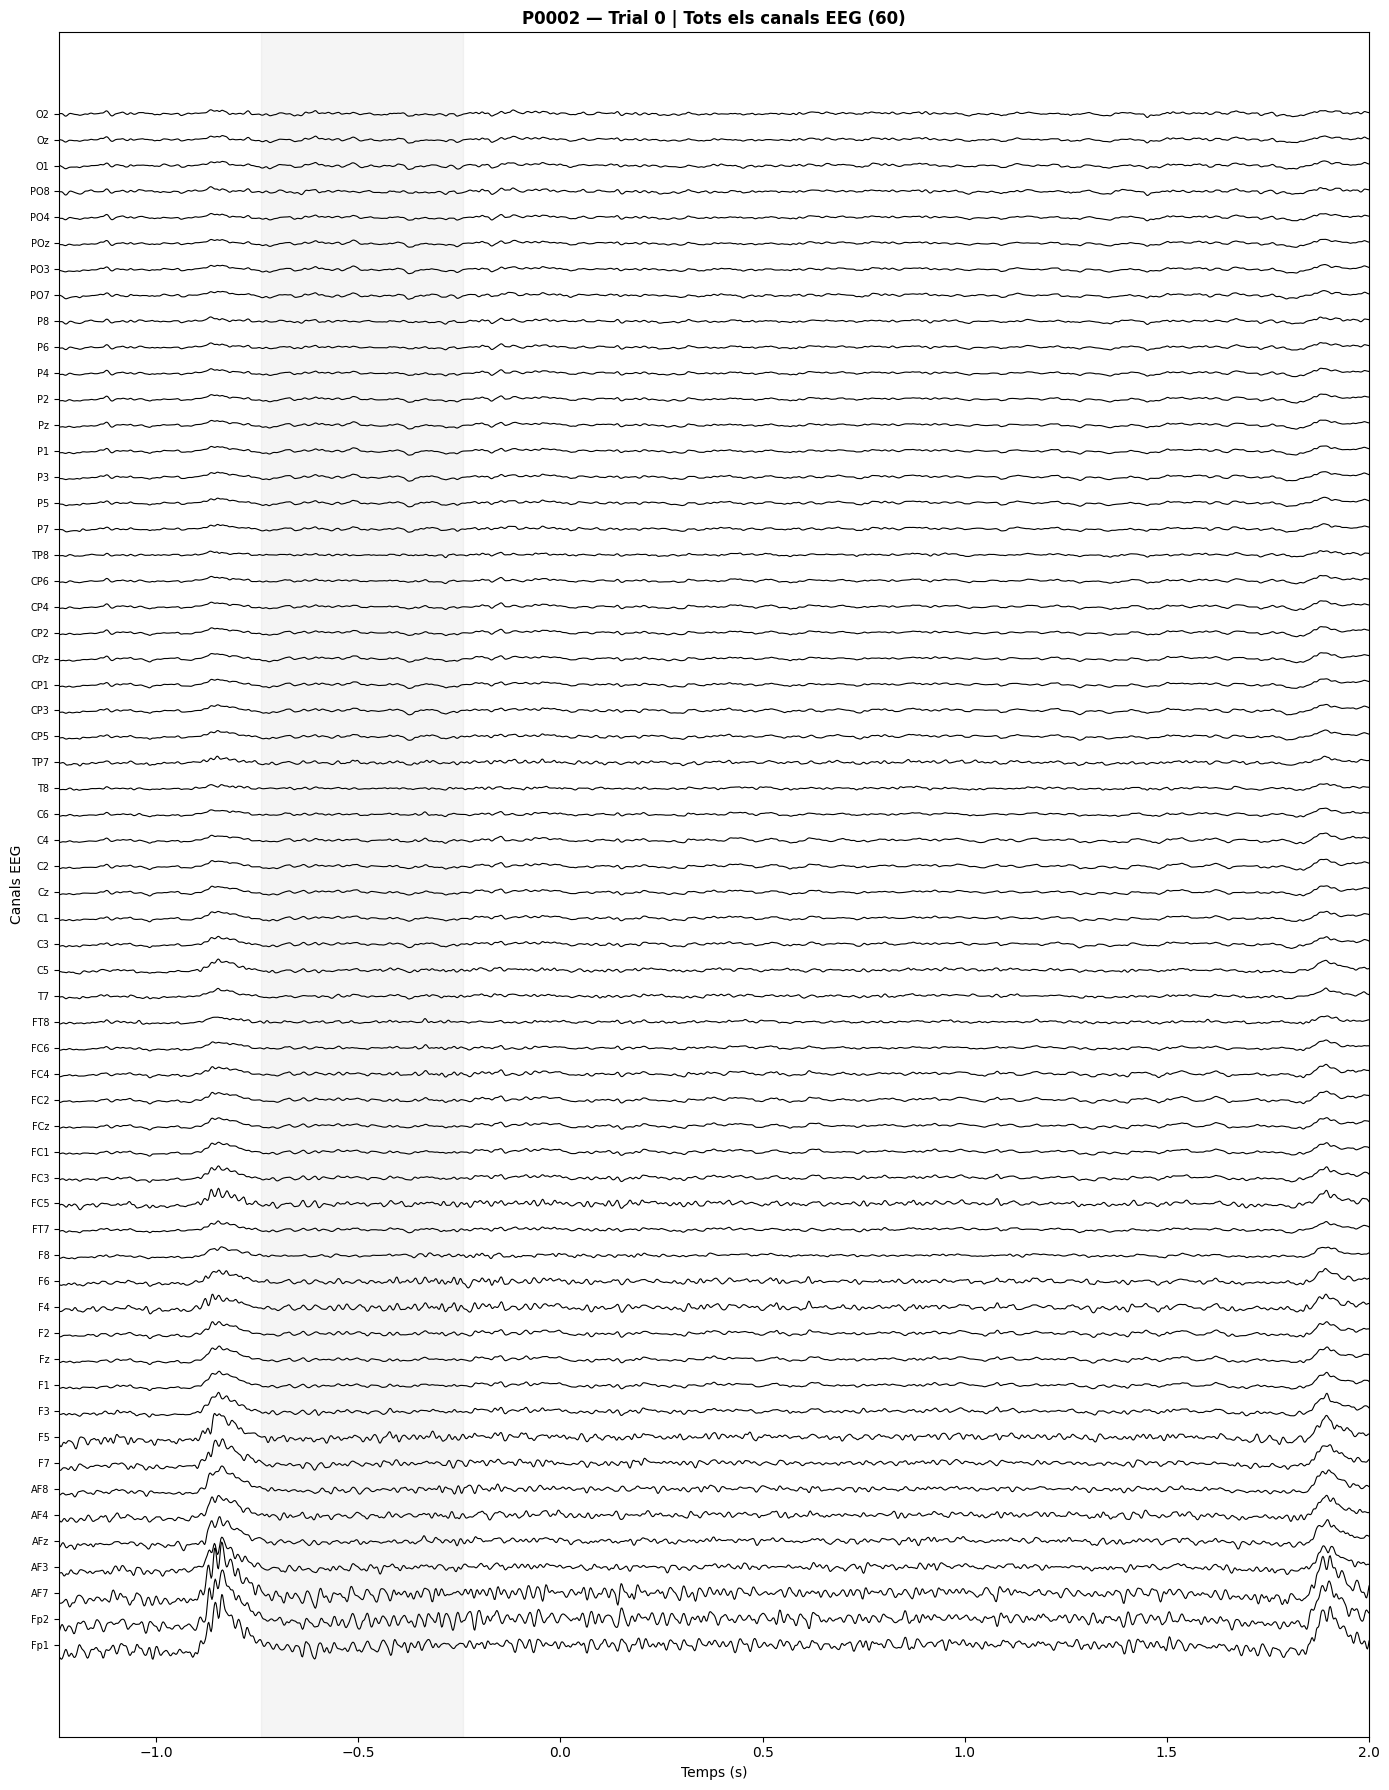

In [6]:
# Llistar i plotar tots els canals EEG de P0002 per a un únic trial
ep_eeg = epochs_all.copy().pick("eeg")
ch_names = ep_eeg.ch_names
n_ch = len(ch_names)

data_uv = ep_eeg.get_data()[1] * 1e6  # (n_ch, n_times) en µV
times = ep_eeg.times

# Offset vertical per separar canals
step = np.percentile(np.ptp(data_uv, axis=1), 75) * 1.5
step = step if step > 0 else 10.0
offsets = np.arange(n_ch) * step

fig, ax = plt.subplots(figsize=(14, 18))
for i, ch in enumerate(ch_names):
    ax.plot(times, data_uv[i] + offsets[i], linewidth=0.8, color="black")

ax.set_yticks(offsets)
ax.set_yticklabels(ch_names, fontsize=7)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)

ax.set_xlim([times[0], times[-1]])
ax.set_xlabel("Temps (s)")
ax.set_ylabel("Canals EEG")
ax.set_title(f"{SUBJ} — Trial 0 | Tots els canals EEG ({n_ch})", fontweight="bold")
plt.tight_layout()
plt.show()

---

## Part 1: Exploració individual (P0002)
Començo amb un sol participant/subjecte per familiaritzar-me amb les dades i fer plots senzills. Després passaré a fer el grand average amb tots els subjectes.

### Desbalanç de classes
Visualització de la distribució de trials per classe al conjunt de dades complet. Això permet veure ràpidament si hi ha desbalanç entre Congruent, Incongruent Pur i Incongruent Mixt.

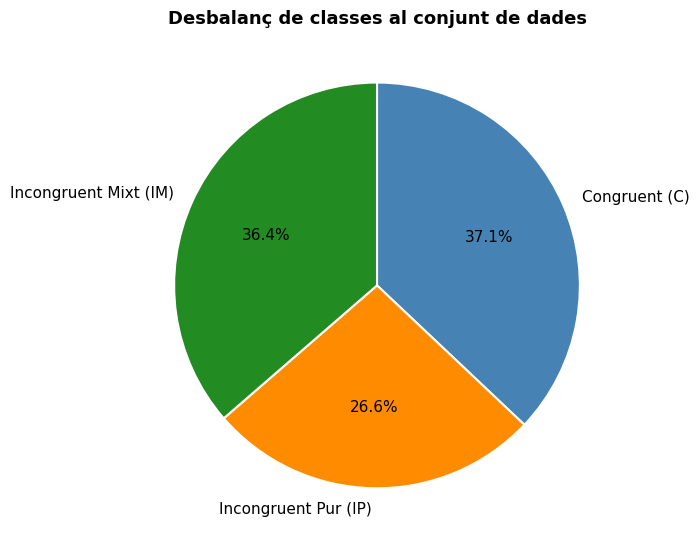

Recompte total per classe:
  Congruent (C)           : 8471 trials ( 37.1%)
  Incongruent Pur (IP)    : 6075 trials ( 26.6%)
  Incongruent Mixt (IM)   : 8314 trials ( 36.4%)


In [7]:
comptes_classes = {cond: 0 for cond in COND_EVENTS}

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    counts_subj = count_trials_by_condition(fif_path)
    for cond in COND_EVENTS:
        comptes_classes[cond] += counts_subj.get(cond, 0)

etiquetes = [LABELS[cond] for cond in comptes_classes]
valors = [comptes_classes[cond] for cond in comptes_classes]
colors = [COLORS[cond] for cond in comptes_classes]
percentatges = np.array(valors) / np.sum(valors) * 100

_, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    valors,
    labels=etiquetes,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontsize": 11},
)

ax.set_title("Desbalanç de classes al conjunt de dades", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Recompte total per classe:")
for etq, n, pct in zip(etiquetes, valors, percentatges):
    print(f"  {etq:24s}: {n:4d} trials ({pct:5.1f}%)")

La classe Incongruent Pur és la menys representada, mentre que Congruent i Incongruent Mixt tenen una quantitat similar de trials. Aquest desbalanç pot afectar les anàlisis i els models predictius, per la qual cosa és important tenir-ho en compte. Mirant les dades, hi ha subjectes que són més desbalancejats que d'altres. N'hi ha que gairebé mai no tenen Incongruent Pur, però sí que tenim 30 trials garantits, ja que es van eliminar els subjectes amb menys de 30 trials per classe al preprocessament.

### ERP (temps vs. voltatge)
Senyal promig ± SEM per Fz, FCz, Cz. Serveix com a sanity check: si l'estímul produeix una resposta evocada clara i coherent entre condicions, les dades estan bé.

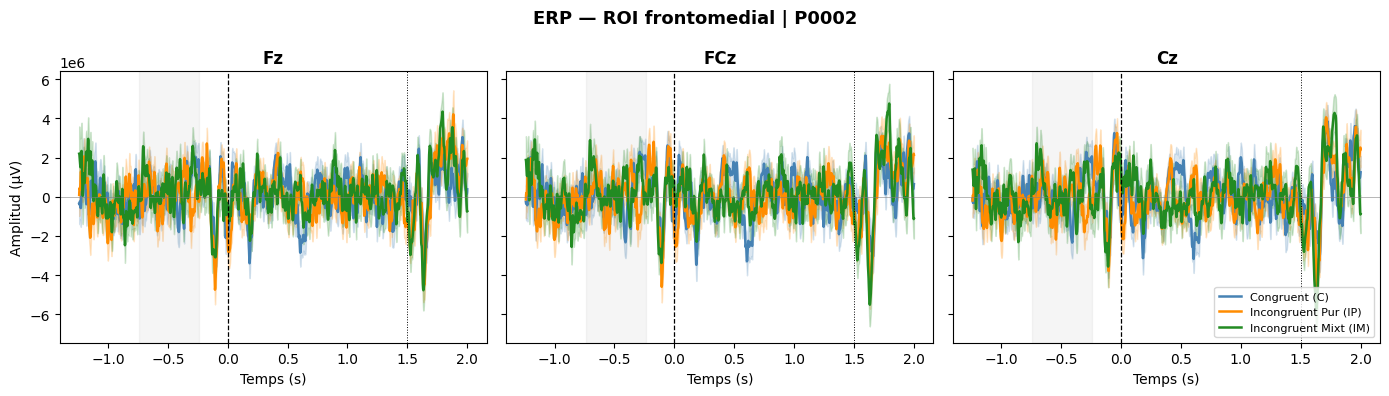

In [8]:
fig, axes = plt.subplots(1, len(ROI_FRONTAL), figsize=(14, 4), sharey=True)
times = epochs_all.times

for ax, ch in zip(axes, ROI_FRONTAL):
    for cond, ep in epochs_cond.items():
        data = ep.get_data(picks=[ch]).squeeze() * 1e6
        mean, sem = data.mean(axis=0), data.std(axis=0) / np.sqrt(len(ep))
        ax.plot(times, mean, label=LABELS[cond], color=COLORS[cond], linewidth=1.8)
        ax.fill_between(times, mean - sem, mean + sem, color=COLORS[cond], alpha=0.2)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.7)
    ax.axhline(0, color="gray", linewidth=0.4)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08)
    ax.set_title(ch, fontsize=12, fontweight="bold")
    ax.set_xlabel("Temps (s)")

axes[0].set_ylabel("Amplitud (µV)")
axes[-1].legend(fontsize=8, loc="lower right")
fig.suptitle(f"ERP — ROI frontomedial | {SUBJ}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Theta power time-course (temps vs. potència, dB)
Potència theta (5–7 Hz) baseline-corregida, promig sobre Fz/FCz/Cz.
**Aquest és el plot central del TFG**: si el conflicte activa el sistema de monitoratge, IP ha de mostrar més potència theta que C durant la presentació de l'estímul.
Equivalent a la Figura 2B de l'article.

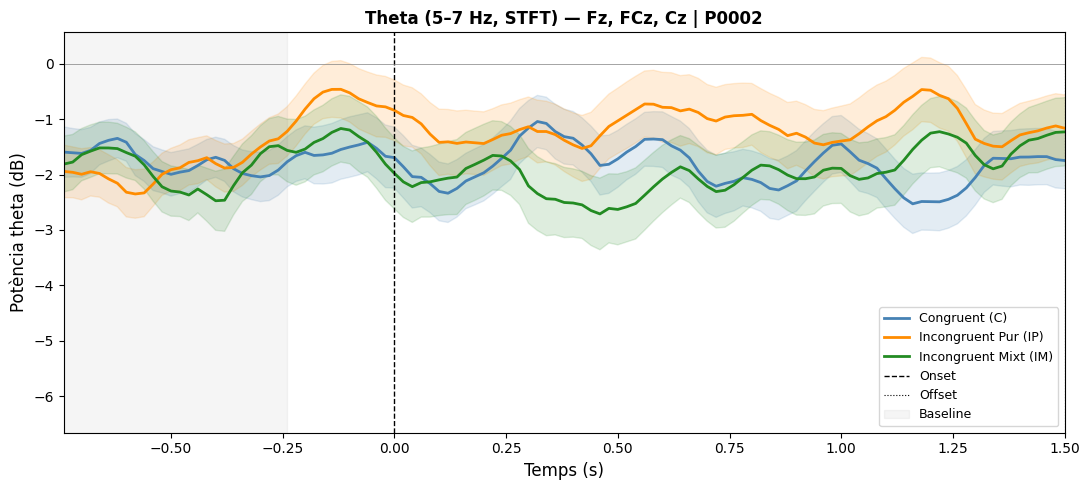

In [9]:
theta_tc = {}
for cond, ep in epochs_cond.items():
    t, mean_ts, sem_ts = stft_band_timecourse(ep, ROI_FRONTAL, band=(5, 7), baseline=BASELINE)
    theta_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in theta_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència theta (dB)", fontsize=12)
ax.set_title(f"Theta (5–7 Hz, STFT) — Fz, FCz, Cz | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.show()

### TFR map diferencial. Figura 3 (A i C)
Diferència de potència (IP−C i IP−IM) per tot l'espectre i tots els elèctrodes. 
Vermell = més potència en IP; blau = menys. Les bandes theta i alpha marcades.

/tmp/ipykernel_601/1021069258.py:31: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axhspan(8, 12, color="white", alpha=0.15, edgecolor="white", linewidth=1.5)
/tmp/ipykernel_601/1021069258.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


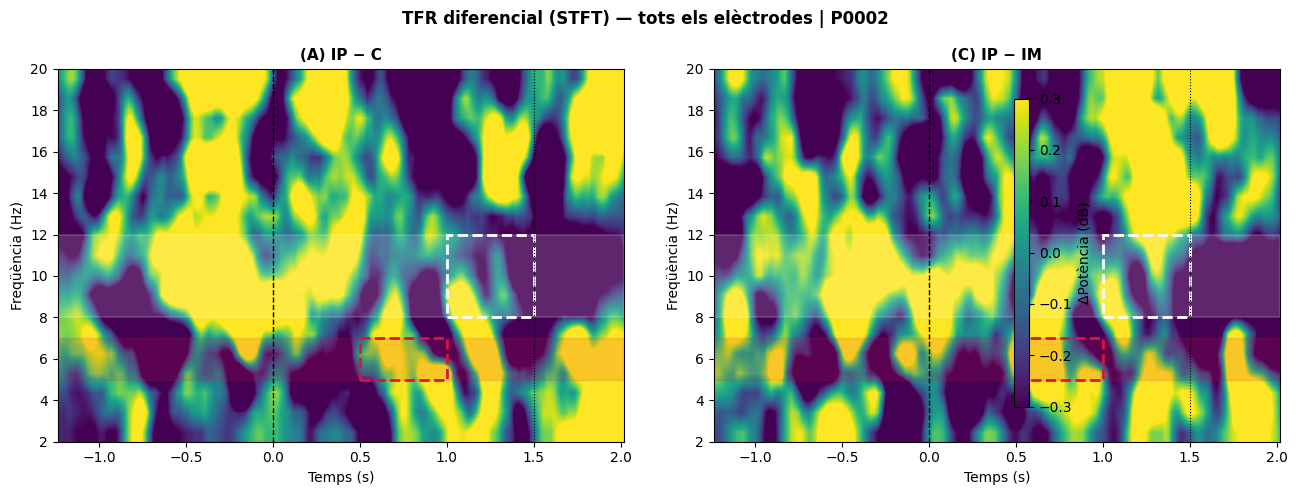

In [10]:
tfr_cond_mean = {}
for cond, ep in epochs_cond.items():
    f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)
    tfr_cond_mean[cond] = {"freqs": f, "times": t, "mean_db": mean_db}  # (n_freq, n_t)

VLIM = 0.3
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]
for ax, (panel, ca, cb, title) in zip(axes, contrasts):
    diff = tfr_cond_mean[ca]["mean_db"] - tfr_cond_mean[cb]["mean_db"]
    # Remove horizontal gradients by subtracting the mean across time at each frequency
    diff = diff - diff.mean(axis=1, keepdims=True)
    t = tfr_cond_mean[ca]["times"]
    f = tfr_cond_mean[ca]["freqs"]
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        extent=[t[0], t[-1], f[0], f[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="bilinear",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.15)
    ax.axhspan(8, 12, color="white", alpha=0.15, edgecolor="white", linewidth=1.5)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="white", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")

fig.colorbar(im, ax=axes.tolist(), label="ΔPotència (dB)", shrink=0.8)
fig.suptitle(f"TFR diferencial (STFT) — tots els elèctrodes | {SUBJ}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Alpha suppression. Figura 4A
Potència alpha (8–12 Hz) sobre ROI parieto-occipital. Supressió alpha = major activació visual.
Hipòtesi: IP i IM haurien de mostrar més supressió (valors més baixos) que C.

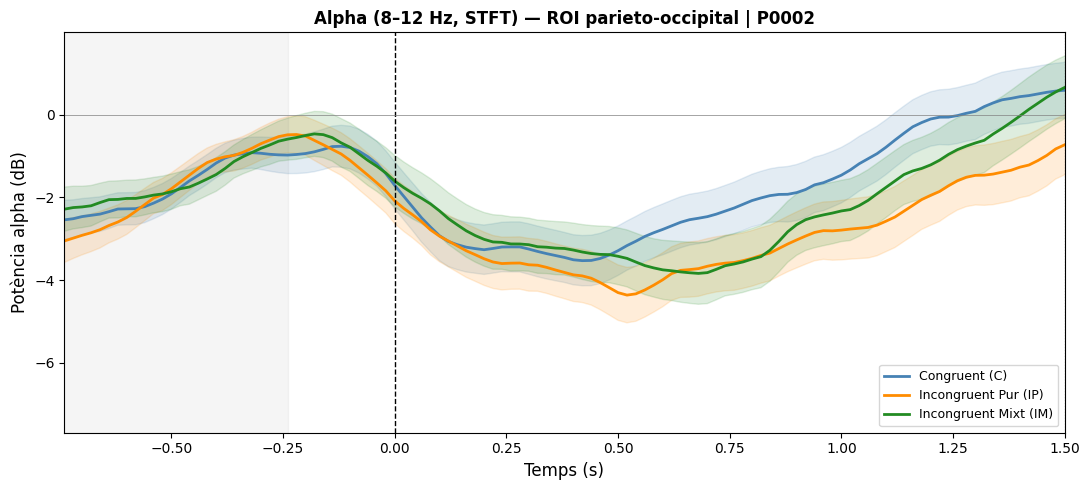

In [11]:
alpha_tc = {}
for cond, ep in epochs_cond.items():
    po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
    if not po_ok:
        continue
    t, mean_ts, sem_ts = stft_band_timecourse(ep, po_ok, band=(8, 12), baseline=BASELINE)
    alpha_tc[cond] = (t, mean_ts, sem_ts)

fig, ax = plt.subplots(figsize=(11, 5))
for cond, (times, power_ts, sem_ts) in alpha_tc.items():
    ax.plot(times, power_ts, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times, power_ts - sem_ts, power_ts + sem_ts, color=COLORS[cond], alpha=0.15)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Potència alpha (dB)", fontsize=12)
ax.set_title(f"Alpha (8–12 Hz, STFT) — ROI parieto-occipital | {SUBJ}", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.set_xlim(FULL_TRIAL)
plt.tight_layout()
plt.show()

---

## Part 2: Mitjana sobre tots els subjectes

El loop carrega cada subjecte, calcula els TFRs theta i alpha, i acumula els time-courses.
Al final es fa la mitjana entre subjectes i es reploten els mateixos gràfics amb SEM real entre subjectes.

In [12]:
# Acumuladors
all_theta = {cond: [] for cond in COND_EVENTS}
all_alpha = {cond: [] for cond in COND_EVENTS}
subjectes_inclosos = []
times_ga = None


def power_ts(ep, picks, band):
    times, mean_ts, _ = stft_band_timecourse(ep, picks, band=band, baseline=BASELINE)
    return times, mean_ts


for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    ep_all, ep_cond = load_subject(fif_path)

    for cond, ep in ep_cond.items():
        # Theta (ROI frontal)
        t, ts = power_ts(ep, ROI_FRONTAL, band=(5, 7))
        all_theta[cond].append(ts)
        if times_ga is None:
            print(f"Guardant times de la GA a partir de {subj_id}...")
            times_ga = t

        # Alpha (ROI parieto-occipital)
        po_ok = [ch for ch in ROI_PO if ch in ep.ch_names]
        if po_ok:
            _, ts = power_ts(ep, po_ok, band=(8, 12))
            all_alpha[cond].append(ts)

    subjectes_inclosos.append(subj_id)
    del ep_cond, ep_all
    gc.collect()

print(f"\nInclosos : {len(subjectes_inclosos)} — {subjectes_inclosos}")

Guardant times de la GA a partir de P0002...

Inclosos : 47 — ['P0002', 'P0003', 'P0004', 'P0005', 'P0009', 'P008', 'P010', 'P011', 'P013', 'P014', 'P015', 'P016', 'P017', 'P020', 'P021', 'P022', 'P023', 'P024', 'P025', 'P027', 'P028', 'P029', 'P030', 'P031', 'P033', 'P035', 'P039', 'P040', 'P041', 'P044', 'P045', 'P046', 'P048', 'P051', 'P053', 'P056', 'P057', 'P058', 'P060', 'P061', 'P062', 'P063', 'P065', 'P066', 'P067', 'P068', 'P069']


### TFR map diferencial (grand average)
Mateix càlcul que al cas individual, però recorrent els subjectes un a un i acumulant només el mapa TFR mitjà per condició per reduir l'ús de memòria.

In [ ]:
ga_tfr_sum = {}
ga_tfr_n = {cond: 0 for cond in COND_EVENTS}
freqs_tfr_ga, times_tfr_ga = None, None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    try:
        for cond, ep in ep_cond.items():
            f, t, mean_db = stft_condition_mean_db_chunked(ep, freqs=FREQS_WIDE, baseline=BASELINE, ch_block=4)

            if cond not in ga_tfr_sum:
                ga_tfr_sum[cond] = np.zeros_like(mean_db, dtype=np.float64)

            ga_tfr_sum[cond] += mean_db
            ga_tfr_n[cond] += 1

            if freqs_tfr_ga is None or times_tfr_ga is None:
                freqs_tfr_ga, times_tfr_ga = f, t
    finally:
        del ep_cond, ep_all
        gc.collect()

tfr_ga_mean = {}
for cond, sum_db in ga_tfr_sum.items():
    if ga_tfr_n[cond] > 0:
        tfr_ga_mean[cond] = sum_db / ga_tfr_n[cond]

if freqs_tfr_ga is None or times_tfr_ga is None:
    raise RuntimeError("No s'ha pogut calcular cap TFR per al grand average.")

VLIM = 0.3
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
contrasts = [
    ("A", "Incongruent_Pur", "Congruent", "IP − C"),
    ("C", "Incongruent_Pur", "Incongruent_Mixt", "IP − IM"),
]

for ax, (panel, ca, cb, title) in zip(axes, contrasts):
    diff = tfr_ga_mean[ca] - tfr_ga_mean[cb]
    diff = diff - diff.mean(axis=1, keepdims=True)
    im = ax.imshow(
        diff,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        extent=[times_tfr_ga[0], times_tfr_ga[-1], freqs_tfr_ga[0], freqs_tfr_ga[-1]],
        vmin=-VLIM,
        vmax=VLIM,
        interpolation="bilinear",
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
    ax.axhspan(5, 7, color="crimson", alpha=0.15)
    ax.axhspan(8, 12, color="white", alpha=0.15, edgecolor="white", linewidth=1.5)
    ax.add_patch(Rectangle((0.5, 5), 0.5, 2, fill=False, edgecolor="crimson", linewidth=2, linestyle="--"))
    ax.add_patch(Rectangle((1.0, 8), 0.5, 4, fill=False, edgecolor="white", linewidth=2, linestyle="--"))
    ax.set_title(f"({panel}) {title}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Freqüència (Hz)")

n_tfr = min(ga_tfr_n[cond] for cond in tfr_ga_mean)
fig.colorbar(im, ax=axes.tolist(), label="ΔPotència (dB)", shrink=0.8)
fig.suptitle(
    f"Grand average — TFR diferencial (STFT), tots els elèctrodes  (N={n_tfr})",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

print("Subjectes contribuents per condició:")
for cond in COND_EVENTS:
    print(f"  {LABELS[cond]:24s}: {ga_tfr_n[cond]:2d}")

### Theta power time-course
Cada línia és la mitjana entre subjectes. L'àrea ombrejada és el SEM entre subjectes (no entre trials ni entre canals com en els plots individuals).

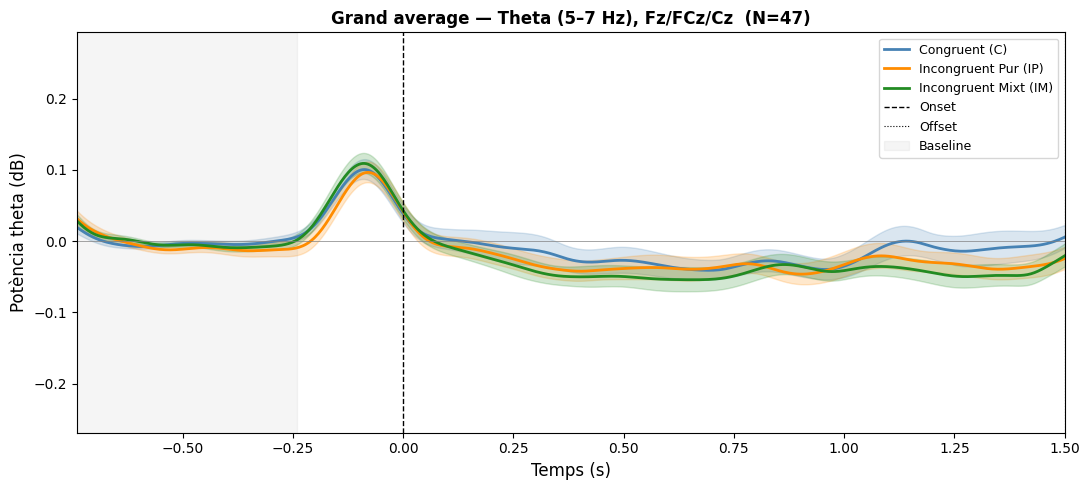

In [ ]:
def plot_timecourse_ga(accumulator, times, ylabel, title):
    """Plot de grand average amb SEM entre subjectes."""
    fig, ax = plt.subplots(figsize=(11, 5))
    n_subj = len(next(iter(accumulator.values())))

    for cond, ts_list in accumulator.items():
        mat = np.array(ts_list)  # (n_subjectes, n_times)
        mean_ga = mat.mean(axis=0)
        sem_ga = mat.std(axis=0) / np.sqrt(len(ts_list))
        ax.plot(times, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
        ax.fill_between(times, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="Onset")
    ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8, label="Offset")
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvspan(*BASELINE, color="gray", alpha=0.08, label="Baseline")
    ax.set_xlabel("Temps (s)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"{title}  (N={n_subj})", fontsize=12, fontweight="bold")
    ax.set_xlim(FULL_TRIAL)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


plot_timecourse_ga(
    all_theta,
    times_ga,
    ylabel="Potència theta (dB)",
    title="Grand average — Theta (5–7 Hz), Fz/FCz/Cz",
)

### Alpha suppression

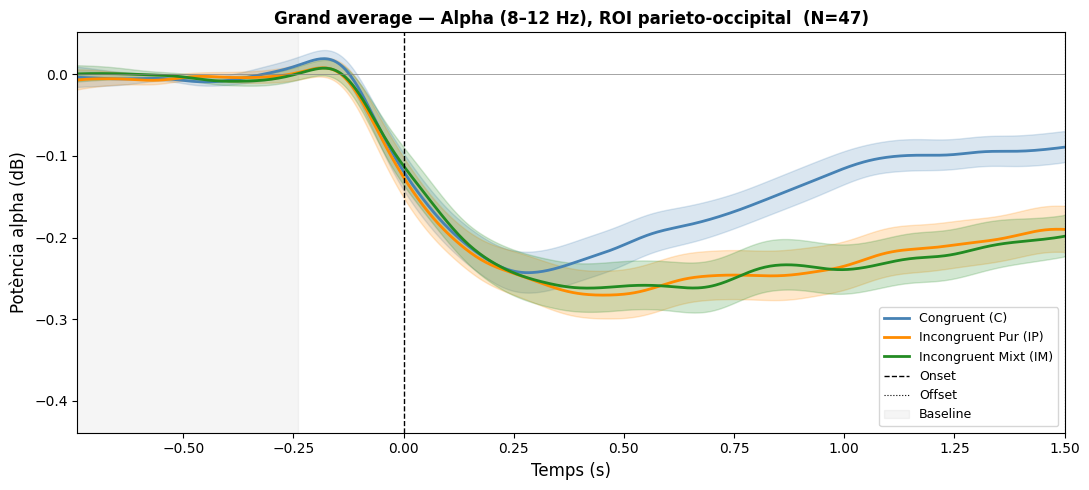

In [ ]:
plot_timecourse_ga(
    all_alpha,
    times_ga,
    ylabel="Potència alpha (dB)",
    title="Grand average — Alpha (8–12 Hz), ROI parieto-occipital",
)

### ERP (Event-Related Potential)
Mitjana del senyal en el domini temporal. Aquí cal recalcular perquè necessitem les dades en brut (µV), no els TFRs.

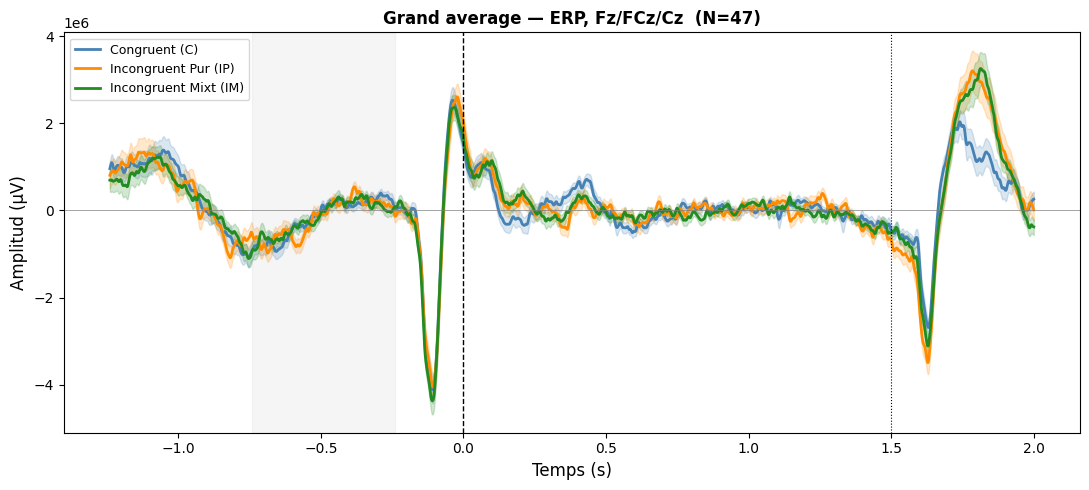

In [ ]:
all_erp = {cond: [] for cond in COND_EVENTS}  # (n_subjectes, n_times) per canal promig
times_erp = None

for fif_path in sorted(DATA_DIR.glob("*.fif")):
    subj_id = fif_path.stem
    if subj_id not in subjectes_inclosos:
        continue

    ep_all, ep_cond = load_subject(fif_path)
    if times_erp is None:
        times_erp = ep_all.times
    for cond, ep in ep_cond.items():
        # Promig sobre trials i sobre canals ROI → (n_times,)
        data = ep.get_data(picks=ROI_FRONTAL).mean(axis=0).mean(axis=0) * 1e6
        all_erp[cond].append(data)

    del ep_cond, ep_all
    gc.collect()

fig, ax = plt.subplots(figsize=(11, 5))
n_subj = len(subjectes_inclosos)
for cond, ts_list in all_erp.items():
    mat = np.array(ts_list)
    mean_ga = mat.mean(axis=0)
    sem_ga = mat.std(axis=0) / np.sqrt(n_subj)
    ax.plot(times_erp, mean_ga, label=LABELS[cond], color=COLORS[cond], linewidth=2)
    ax.fill_between(times_erp, mean_ga - sem_ga, mean_ga + sem_ga, color=COLORS[cond], alpha=0.2)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.axvline(1.5, color="black", linestyle=":", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvspan(*BASELINE, color="gray", alpha=0.08)
ax.set_xlabel("Temps (s)", fontsize=12)
ax.set_ylabel("Amplitud (µV)", fontsize=12)
ax.set_title(f"Grand average — ERP, Fz/FCz/Cz  (N={n_subj})", fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()